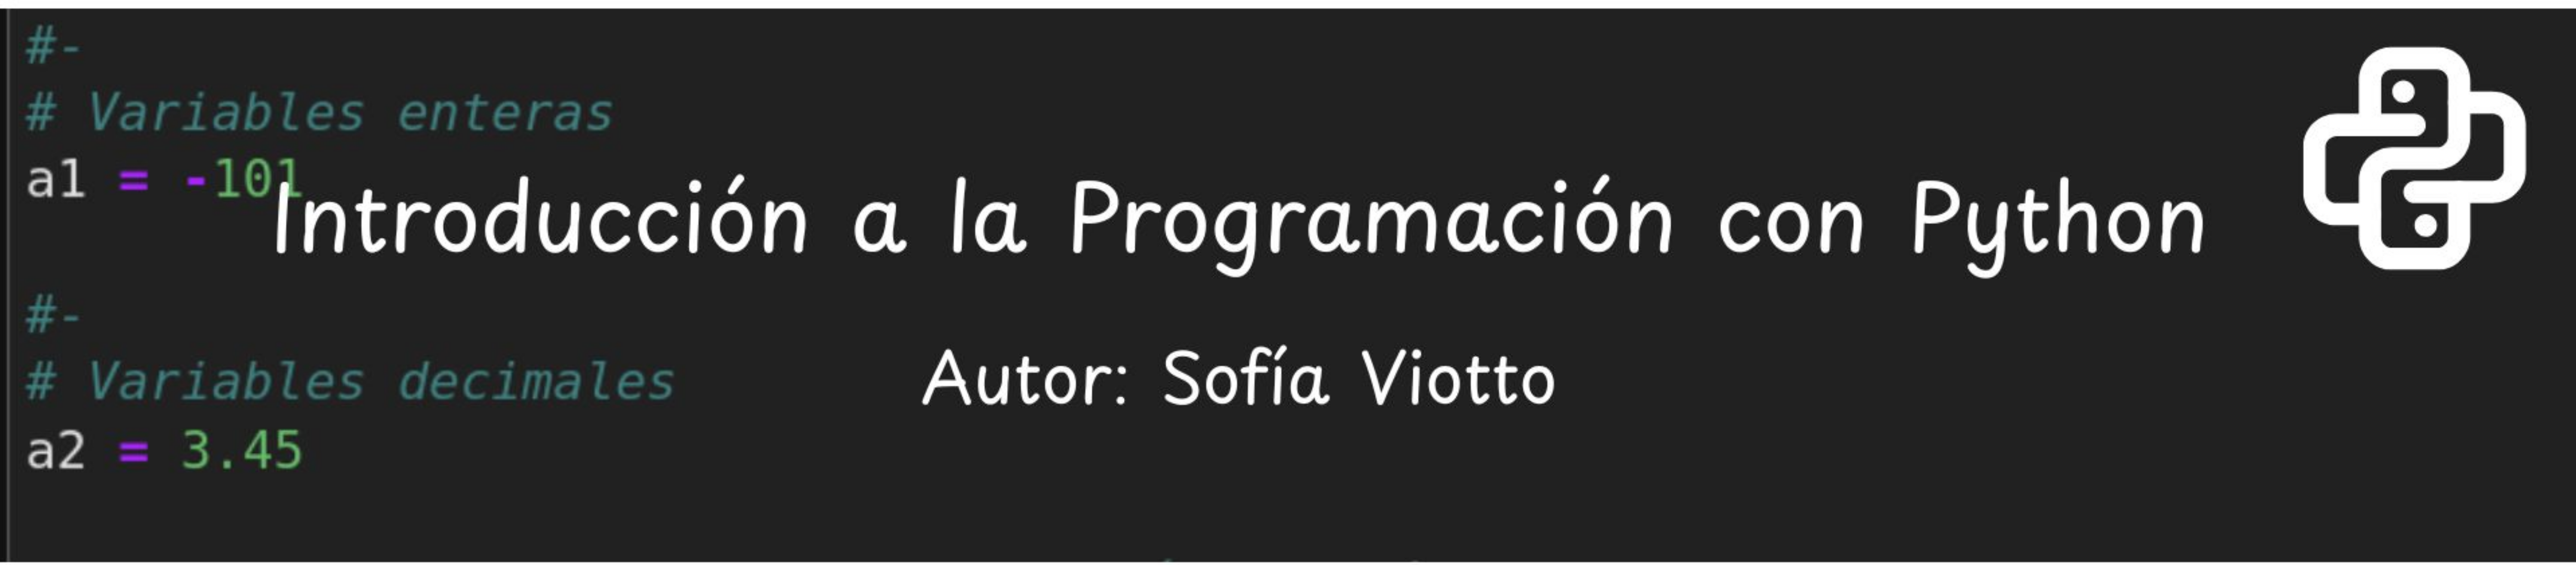

**Jupyter Notebook 5 de 6**


# Pandas

[Pandas](https://pandas.pydata.org/) una de las librerías básicas de Python, que permiten una manipulación eficiente de datos. Esta librería se complementa muy bien con como NumPy (abordado en el Notebook anterior) y con Matplotlib. 

# Dataframes 

Los dataframes de Pandas son uno de los principales objetos de Pandas. Ellos constituyen tablas de datos, de modo que a cada columna y a cada fila se le asigna una etiqueta o nombre. Podemos pensar en ellos como tablas en hojas de cálculo.

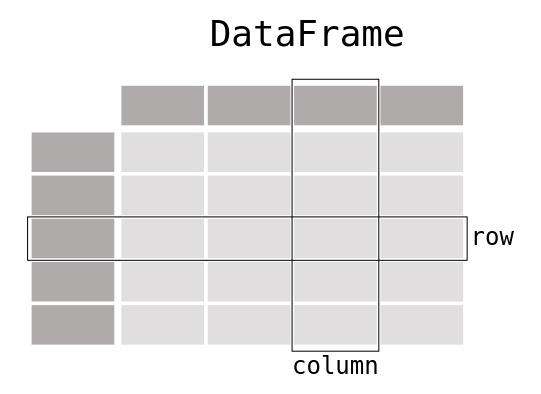

(Fuente: [Pandas-Tutorial](https://pandas.pydata.org/docs/getting_started/intro_tutorials/01_table_oriented.html))




In [1]:
import pandas as pd
import numpy as np

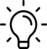 Vamos a crear un dataframe que contenga dos columnas, la primera contendrá el nombre de los diamantes en bruto más grandes encontrados en la historia de la humanidad y la segunda sus quilates.


In [3]:
# Crear dos listas
diam = [ "Sergio", "Cullinan", "Motswedi", "Sewelo",
           "Lesedi La Rona", "Excelsior", "Star of Sierra Leone"]
quil = [ 3245, 3106, 2492, 1758, 1109, 995, 9689 ]

#Indices
siglas=["SRG", "CLN", "MTW", "SWL", "LLR", "EXR","SSL"]


df0 = pd.DataFrame({"Nombre" : diam,
                    "Quilates": quil}, index=siglas)

In [4]:
df0

,Nombre,Quilates
SRG,Sergio,3245
CLN,Cullinan,3106
MTW,Motswedi,2492
SWL,Sewelo,1758
LLR,Lesedi La Rona,1109
EXR,Excelsior,995
SSL,Star of Sierra Leone,9689


# Atributos de un Dataframe

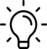 Emplearemos diferentes funciones para inspeccionar nuestras tablas.


In [9]:
# Obtener información sobre el tipo de dato en cada columna
df0.dtypes

Nombre        str
Quilates    int64
dtype: object

In [ ]:
# Información básica sobre la tabla
df0.info()

In [ ]:
# Visualizar las primeras columnas
df0.head()

In [ ]:
# Visualizar las últimas columnas especificadas entre paréntesis
# df0.tail(1), df0.tail(4)...
df0.tail(2)

In [ ]:
# Obtener las columnas
df0.columns

In [ ]:
# Obtener los íncides
df0.index

In [10]:
# Obtener la cantidad de elementos y las dimensiones
# Resultado (filas, columnas)
df0.shape

(7, 2)

# Indexar y Extraer Subdataframes

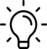 Indexar con las etiquetas de las columnas


In [11]:
# Extraer una columna
df0['Nombre']

SRG                  Sergio
CLN                Cullinan
MTW                Motswedi
SWL                  Sewelo
LLR          Lesedi La Rona
EXR               Excelsior
SSL    Star of Sierra Leone
Name: Nombre, dtype: str

<img src="figuras/icono_lampara.png" width="5%"> Indexar con el método **<font color='maroon'>.loc</font>**

In [ ]:
# Extraer la fila cero con loc
df0.loc["SRG"]

In [ ]:
# Extraer un fragmento (slice) del dataframe, 
# con todas las filas entre esos dos extremos
df0.loc["SRG":"SWL"]

In [ ]:
# Extraer solo las filas mencionadas
df0.loc[["SRG", "SWL"]]

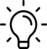 Indexar con el método **<font color='maroon'>.iloc</font>**, extrayendo de acuerdo al índice de cada fila

In [ ]:
# Extraer la fila cero 
df0.iloc[0]

In [ ]:
# Extraer la columna cero
df0.iloc[:,0]

In [ ]:
# Extraer un elemento
df0.iloc[0,1]

# Mutabilidad

Antes de revisar algunas funciones que podemos ejecutar con tablas, conviene estudiar la mutabilidad de las tablas.

In [ ]:
df1 = df0

print( id(df0) == id(df1))

In [ ]:
# Para hacer copias verdaderas en la memoria
df1 = df0.copy()

print( id(df0) == id(df1))

# Operaciones

##  Aritméticas 

Podemos realizar operaciones aritméticas con nuestro dataframes, siempre que los datos almacenados sean de tipo numérico.

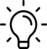 Vamos a crear una nueva columna para convertir de quilates a gramos. Para eso empleamos la siguiente relación:

 **1 quilate = 0.2 g**


In [ ]:
# Guardar la conversión en una nueva columna
df0["Gramo"] = df0["Quilates"]*0.2

In [ ]:
df0

### <img src="figuras/icono_cuaderno.png" width="4%">  Desafío
Crea una nueva columna que se llame "Kilogramo" y convierte el peso de los diamantes de gramo a kilogramo.

## Reducción

Estas operaciones son similares a las operaciones que podemos realizar con los arreglos de NumPy.

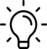 Describir la tabla y realizar operaciones de reducción


In [ ]:
# Devuelve una estadística descriptiva de la tabla
df0.describe()

In [ ]:
# Otras operaciones
print('Suma',df0["Quilates"].sum())

print('Promedio',df0["Quilates"].mean())


In [ ]:
df0["Quilates"].std()

## De Dataframe a Array
Dada la compatibilidad entre NumPy y Pandas, existen numerosas funciones que nos permiten convertir tablas en arreglos, o arreglos en tablas

In [14]:
# Convertir dataframe a array
#Tomando solo las columnas numéricas
a0 = df0.iloc[:,1:].values
print(a0)
print (type (a0))

[[3245]
 [3106]
 [2492]
 [1758]
 [1109]
 [ 995]
 [9689]]
<class 'numpy.ndarray'>


In [13]:
# Convertir un array a dataframe
a1 = np.arange(6).reshape(3,2)
df1 = pd.DataFrame(a1,
                   columns= ["A", "B"],
                   index = [1, 2, 3])

print(df1)


   A  B
1  0  1
2  2  3
3  4  5


# Exportar e Importar Datos 

En ocasiones, necesitamos importar y exportar datos con Pandas.

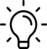 Exportemos el dataframe que creamos con anterioridad


In [15]:
# Hay distintos formatos
# El más común es el formato csv
df0.to_csv('primera_base_datos.csv')

In [16]:
#Abrimos esta base de datos
df_n=pd.read_csv('primera_base_datos.csv', index_col=0)
print(df_n)

                   Nombre  Quilates
SRG                Sergio      3245
CLN              Cullinan      3106
MTW              Motswedi      2492
SWL                Sewelo      1758
LLR        Lesedi La Rona      1109
EXR             Excelsior       995
SSL  Star of Sierra Leone      9689
